In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from keras.layers import Input, Dense, Dropout, BatchNormalization
from keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, roc_curve
from keras.models import Sequential

In [3]:
df = pd.read_csv('/kaggle/input/datasets/samvelgalstyan/loantrain/train.csv')

In [4]:
df

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
593989,593989,23004.26,0.152,703,20958.37,10.92,Female,Single,High School,Employed,Business,C3,1.0
593990,593990,35289.43,0.105,559,3257.24,14.62,Male,Single,Bachelor's,Employed,Debt consolidation,F5,1.0
593991,593991,47112.64,0.072,675,929.27,14.13,Female,Married,Bachelor's,Employed,Debt consolidation,C1,1.0
593992,593992,76748.44,0.067,740,16290.40,9.87,Male,Single,Bachelor's,Employed,Debt consolidation,B2,1.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 593994 entries, 0 to 593993
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    593994 non-null  int64  
 1   annual_income         593994 non-null  float64
 2   debt_to_income_ratio  593994 non-null  float64
 3   credit_score          593994 non-null  int64  
 4   loan_amount           593994 non-null  float64
 5   interest_rate         593994 non-null  float64
 6   gender                593994 non-null  object 
 7   marital_status        593994 non-null  object 
 8   education_level       593994 non-null  object 
 9   employment_status     593994 non-null  object 
 10  loan_purpose          593994 non-null  object 
 11  grade_subgrade        593994 non-null  object 
 12  loan_paid_back        593994 non-null  float64
dtypes: float64(5), int64(2), object(6)
memory usage: 58.9+ MB


In [6]:
df = df.drop('id',axis=1)

In [7]:
X = df.drop('loan_paid_back',axis=1)
y = df['loan_paid_back']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
num_cols = X_train.select_dtypes('int','float').columns
str_cols = X_train.select_dtypes('object').columns
num_cols_binary = [i for i in num_cols if X_train[i].max() <= 1]
num_cols_numeric = [j for j in num_cols if X_train[j].max() > 1]

In [10]:
preprocessor = ColumnTransformer([
   ( 'cat', OneHotEncoder(drop='first', handle_unknown='ignore'), str_cols),
    ('num_scale', StandardScaler(), num_cols_numeric),
    ('num_unscale', 'passthrough', num_cols_binary)
])

In [11]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [23]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(128, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [27]:
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics = ['auc'])

In [28]:
model.fit(X_train,y_train, validation_split=0.15, epochs=15)

Epoch 1/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 31s 2ms/step - auc: 0.8546 - loss: 0.3068 - val_auc: 0.8642 - val_loss: 0.2997
Epoch 2/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8608 - loss: 0.3007 - val_auc: 0.8645 - val_loss: 0.2984
Epoch 3/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8619 - loss: 0.3000 - val_auc: 0.8653 - val_loss: 0.2981
Epoch 4/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8624 - loss: 0.2993 - val_auc: 0.8652 - val_loss: 0.2981
Epoch 5/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8628 - loss: 0.2989 - val_auc: 0.8654 - val_loss: 0.2975
Epoch 6/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8630 - loss: 0.2987 - val_auc: 0.8657 - val_loss: 0.2976
Epoch 7/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8632 - loss: 0.2985 - val_auc: 0.8653 - val_loss: 0.2977
Epoch 8/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - auc: 0.8635 - loss: 0.2983 - val_auc: 0.8653 - val_loss: 0.2977
Epoch 9/15
12623

In [29]:
y_pred = model.predict(X_test).ravel()

3713/3713 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step


In [30]:
fpr, tpr, threshold = roc_curve(y_test, y_pred)

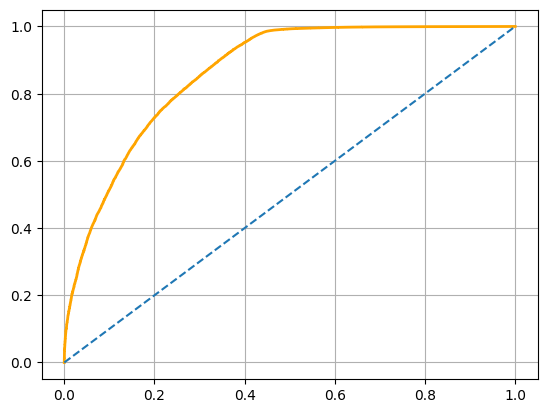

In [31]:
plt.plot(fpr, tpr, color='orange', linewidth=2)
plt.plot([0,1],[0,1], linestyle='dashed')
plt.grid(True)

In [32]:
youden = np.argmax(tpr - fpr)
best_threshold = threshold[youden]

In [33]:
y_pred = (y_pred > best_threshold).astype(int)

In [34]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       0.67      0.64      0.65     23997
         1.0       0.91      0.92      0.91     94802

    accuracy                           0.86    118799
   macro avg       0.79      0.78      0.78    118799
weighted avg       0.86      0.86      0.86    118799



In [35]:
confusion_matrix(y_test,y_pred)

array([[15291,  8706],
       [ 7652, 87150]])

In [41]:
cm = confusion_matrix(y_test, y_pred)

labels = np.array([
    [f"TN\n(True Negative)\n\n{cm[0,0]:,}", f"FP\n(False Positive)\n\n{cm[0,1]:,}"],
    [f"FN\n(False Negative)\n\n{cm[1,0]:,}", f"TP\n(True Positive)\n\n{cm[1,1]:,}"]
])

Text(0.5, 23.52222222222222, 'Предсказанные значения')

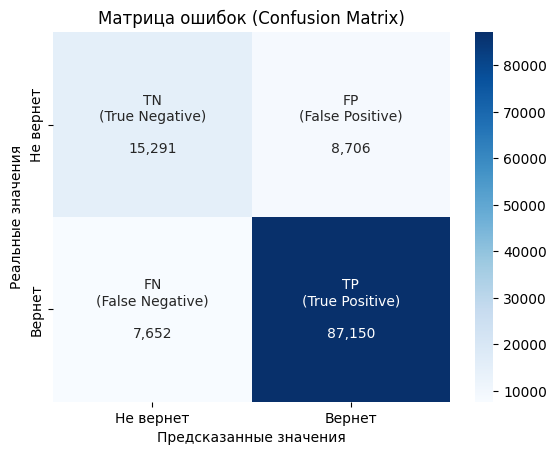

In [42]:
sns.heatmap(
    cm, 
    cmap='Blues', 
    annot=labels, 
    fmt='',
    xticklabels=['Не вернет', 'Вернет'], 
    yticklabels=['Не вернет', 'Вернет'] 
)
plt.title('Матрица ошибок (Confusion Matrix)')
plt.ylabel('Реальные значения')
plt.xlabel('Предсказанные значения')


In [43]:
model.save('model_weights.keras')